# 07 · Strata: urbanity, vulnerability, tribal status and hazards

The tract-level context that the challenge asks about: how urban or rural tracts are, how socially and climatically vulnerable, which are tribal, and what hazards they face. These are the groups whose coverage we will compare in notebook 08.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pathlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "data").exists())
DATA, OUT, ANALYSIS = ROOT / "data", ROOT / "eda_outputs", ROOT / "analysis_outputs"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25, "axes.titlesize": 11, "axes.labelsize": 9})
REG = ["maricopa-az", "northern-ca", "eastern-ok", "south-central-tx", "eastern-wa"]
NAME = {"maricopa-az": "Maricopa AZ", "northern-ca": "Northern CA", "eastern-ok": "Eastern OK", "south-central-tx": "S-C Texas", "eastern-wa": "Eastern WA"}
COL = dict(zip(REG, ["#e07b39", "#c0504d", "#6a9e4f", "#3b6fb6", "#8e6bbf"]))
df = pd.read_parquet(OUT / "base_table.parquet")

def box_by_region(ax, col, log=False, title="", ylabel=None, data=None):
    d = df if data is None else data
    vals = [d.loc[d.region == r, col].dropna() for r in REG]
    if log: vals = [np.log10(v[v > 0]) for v in vals]
    bp = ax.boxplot(vals, patch_artist=True, medianprops=dict(color="k"), flierprops=dict(marker=".", markersize=2, alpha=.3))
    for patch, r in zip(bp["boxes"], REG): patch.set_facecolor(COL[r]); patch.set_alpha(.75)
    ax.set_xticks(range(1, 6)); ax.set_xticklabels([f"{NAME[r]}\nn={len(v):,}" for r, v in zip(REG, vals)], fontsize=7.5)
    ax.set_title(title); ax.set_ylabel(ylabel or (("log10 " if log else "") + col))

def n_outliers(s):
    s = s.dropna(); q1, q3 = s.quantile([.25, .75]); k = 1.5 * (q3 - q1)
    return int(((s < q1 - k) | (s > q3 + k)).sum())

def heat(ax, M, fmt="{:.2f}", cmap="RdBu_r", vmin=-1, vmax=1, fs=7, rot=60):
    im = ax.imshow(M.values, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto"); ax.grid(False)
    ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(M.columns, rotation=rot, ha="right", fontsize=8)
    ax.set_yticks(range(M.shape[0])); ax.set_yticklabels(M.index, fontsize=8)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.values[i, j]; ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=fs, color="k" if abs(v - (vmin + vmax) / 2) < (vmax - vmin) * .35 else "w")
    return im

## 1. Who lives here: population, urbanity, RUCA

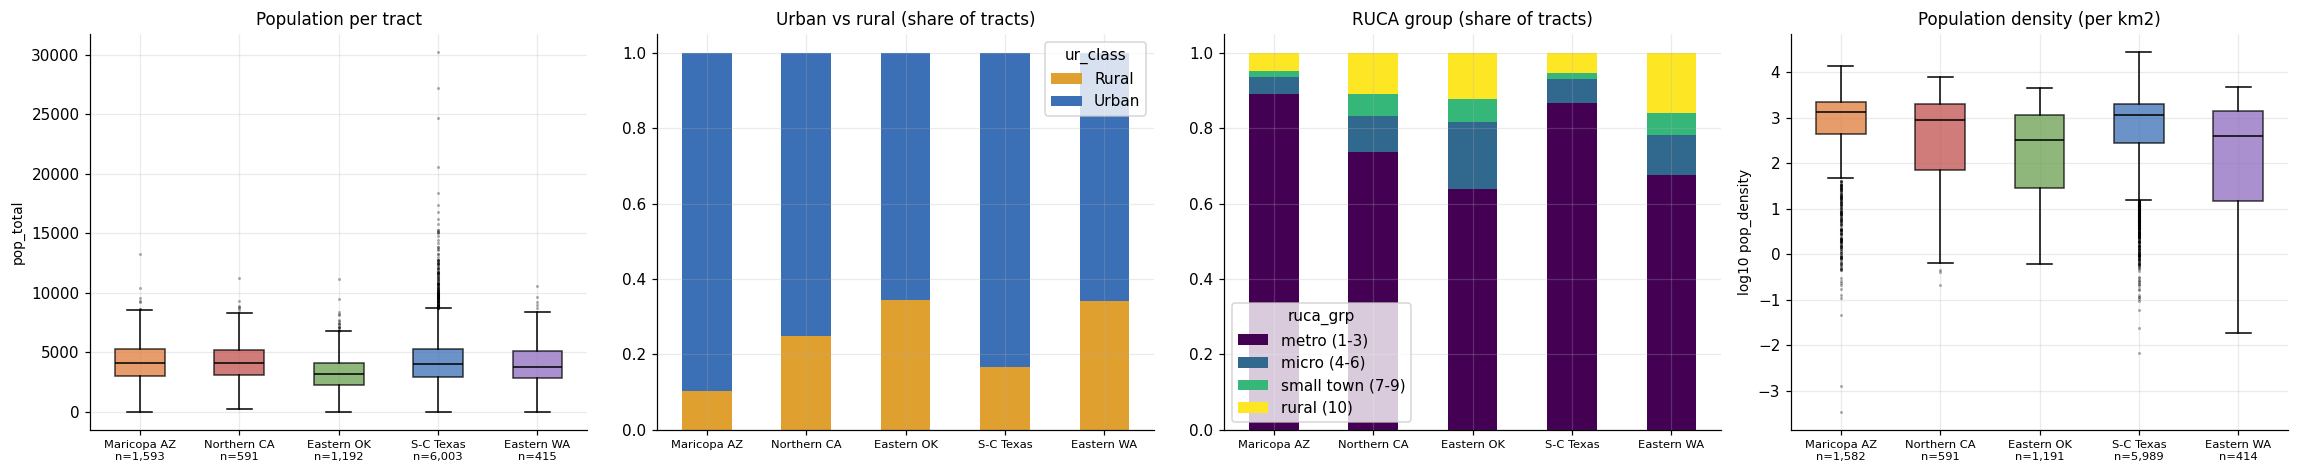

ur_class          Rural  Urban
region                        
maricopa-az        10.0   90.0
northern-ca        25.0   75.0
eastern-ok         35.0   65.0
south-central-tx   17.0   83.0
eastern-wa         34.0   66.0

region
maricopa-az          6606494
northern-ca          2458891
eastern-ok           3926466
south-central-tx    25758569
eastern-wa           1676917

missing ur_class: 27 | missing RUCA: 0


In [2]:
df["ruca_grp"] = pd.cut(df.ruca_primary, [0, 3, 6, 9, 10], labels=["metro (1-3)", "micro (4-6)", "small town (7-9)", "rural (10)"])
fig, ax = plt.subplots(1, 4, figsize=(21, 4.4)); box_by_region(ax[0], "pop_total", title="Population per tract")
pd.crosstab(df.region, df.ur_class, normalize="index").reindex(REG).plot.bar(stacked=True, ax=ax[1], rot=0, color=["#e0a030", "#3b6fb6"]); ax[1].set_title("Urban vs rural (share of tracts)")
pd.crosstab(df.region, df.ruca_grp, normalize="index").reindex(REG).plot.bar(stacked=True, ax=ax[2], rot=0, colormap="viridis"); ax[2].set_title("RUCA group (share of tracts)")
box_by_region(ax[3], "pop_density", log=True, title="Population density (per km2)")
for a in ax[1:3]: a.set_xticklabels([NAME[r] for r in REG], fontsize=7.5); a.set_xlabel("")
plt.tight_layout(); plt.show(); print((pd.crosstab(df.region, df.ur_class, normalize="index").reindex(REG) * 100).round(0).to_string()); print(); print(df.groupby("region").pop_total.sum().reindex(REG).astype(int).to_string()); print("\nmissing ur_class:", int(df.ur_class.isna().sum()), "| missing RUCA:", int(df.ruca_primary.isna().sum()))

**Takeaway:** the scored tracts hold 40.4 million people, 64% of them in Texas (25.8 million). Maricopa is 90% urban, Texas 83%, and Eastern OK and Eastern WA about a third rural (35% and 34%). 27 tracts have no urban/rural class (zero residents). Population per tract is similar everywhere by design, so density differences come from land area.

## 2. Social and climate vulnerability (SVI and CVI)

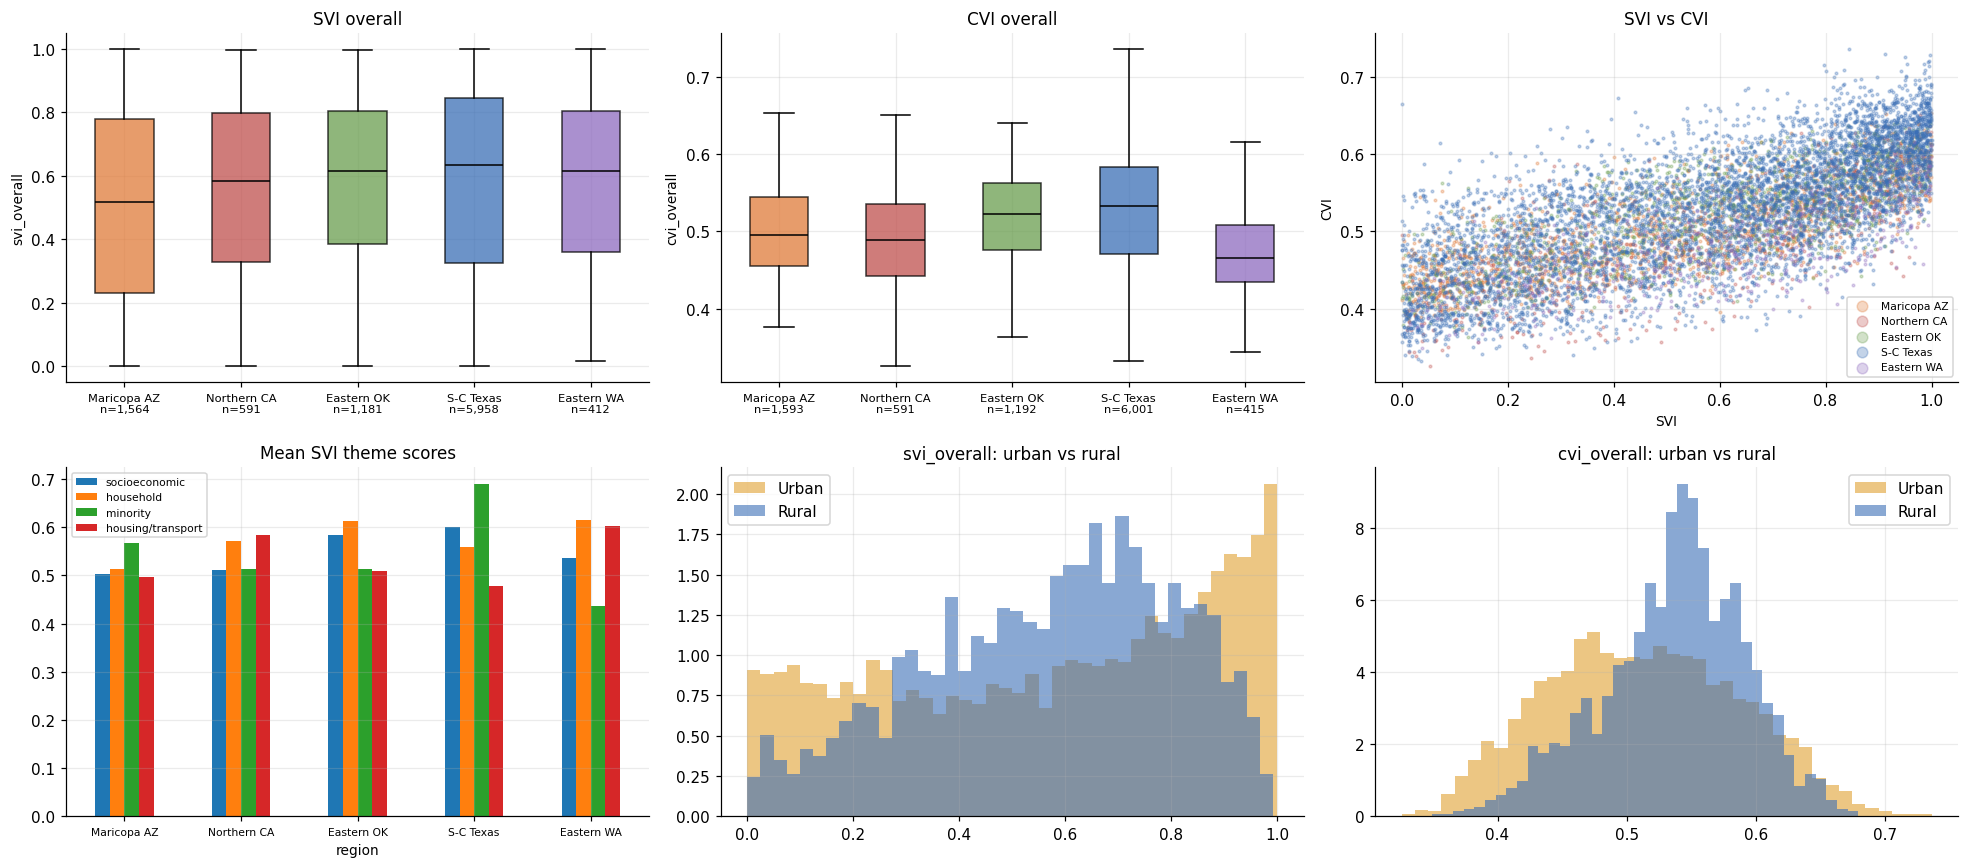

                  svi_overall  cvi_overall
region                                    
maricopa-az              0.52         0.50
northern-ca              0.59         0.49
eastern-ok               0.62         0.52
south-central-tx         0.63         0.53
eastern-wa               0.62         0.47

SVI across regions: ANOVA F = 18.8, p = 2.2e-15, eta2 = 0.008 | Spearman SVI-CVI = 0.73
SVI urban vs rural (median): {'Rural': 0.6, 'Urban': 0.62} | CVI: {'Rural': 0.54, 'Urban': 0.51}


In [3]:
fig, ax = plt.subplots(2, 3, figsize=(18, 8)); box_by_region(ax[0, 0], "svi_overall", title="SVI overall"); box_by_region(ax[0, 1], "cvi_overall", title="CVI overall")
for r in REG: d_ = df[df.region == r]; ax[0, 2].scatter(d_.svi_overall, d_.cvi_overall, s=3, alpha=.3, color=COL[r], label=NAME[r])
ax[0, 2].set(xlabel="SVI", ylabel="CVI", title="SVI vs CVI"); ax[0, 2].legend(markerscale=4, fontsize=7)
th = ["svi_socioeconomic", "svi_household", "svi_minority", "svi_housing_transport"]; m = df.groupby("region")[th].mean().reindex(REG); m.columns = ["socioeconomic", "household", "minority", "housing/transport"]
m.plot.bar(ax=ax[1, 0], rot=0); ax[1, 0].set_xticklabels([NAME[r] for r in REG], fontsize=7); ax[1, 0].set_title("Mean SVI theme scores"); ax[1, 0].legend(fontsize=7)
for a, c in zip(ax[1, 1:], ["svi_overall", "cvi_overall"]):
    for u, col in (("Urban", "#e0a030"), ("Rural", "#3b6fb6")): a.hist(df[df.ur_class == u][c].dropna(), bins=40, alpha=.6, color=col, label=u, density=True)
    a.legend(); a.set_title(f"{c}: urban vs rural")
plt.tight_layout(); plt.show()
g = [df.loc[df.region == r, "svi_overall"].dropna() for r in REG]; allv = pd.concat(g); F, p = stats.f_oneway(*g); eta2 = sum(len(x) * (x.mean() - allv.mean()) ** 2 for x in g) / ((allv - allv.mean()) ** 2).sum()
print(df.groupby("region")[["svi_overall", "cvi_overall"]].median().reindex(REG).round(2).to_string()); print(f"\nSVI across regions: ANOVA F = {F:.1f}, p = {p:.1e}, eta2 = {eta2:.3f} | Spearman SVI-CVI = {stats.spearmanr(df.svi_overall, df.cvi_overall, nan_policy='omit')[0]:.2f}")
print("SVI urban vs rural (median):", df.groupby("ur_class").svi_overall.median().round(2).to_dict(), "| CVI:", df.groupby("ur_class").cvi_overall.median().round(2).to_dict())

**Takeaway:** social vulnerability (SVI) is high almost everywhere (regional medians 0.52 in Maricopa to 0.63 in Texas) and barely separates the regions: ANOVA is significant (F = 18.8) but region explains only 0.8% of the variance (eta-squared 0.008). SVI is essentially unrelated to urbanity (median 0.62 urban vs 0.60 rural), while climate vulnerability (CVI) is slightly higher in rural tracts (0.54 vs 0.51). SVI and CVI are related but not the same (Spearman 0.73).

## 3. Tribal tracts

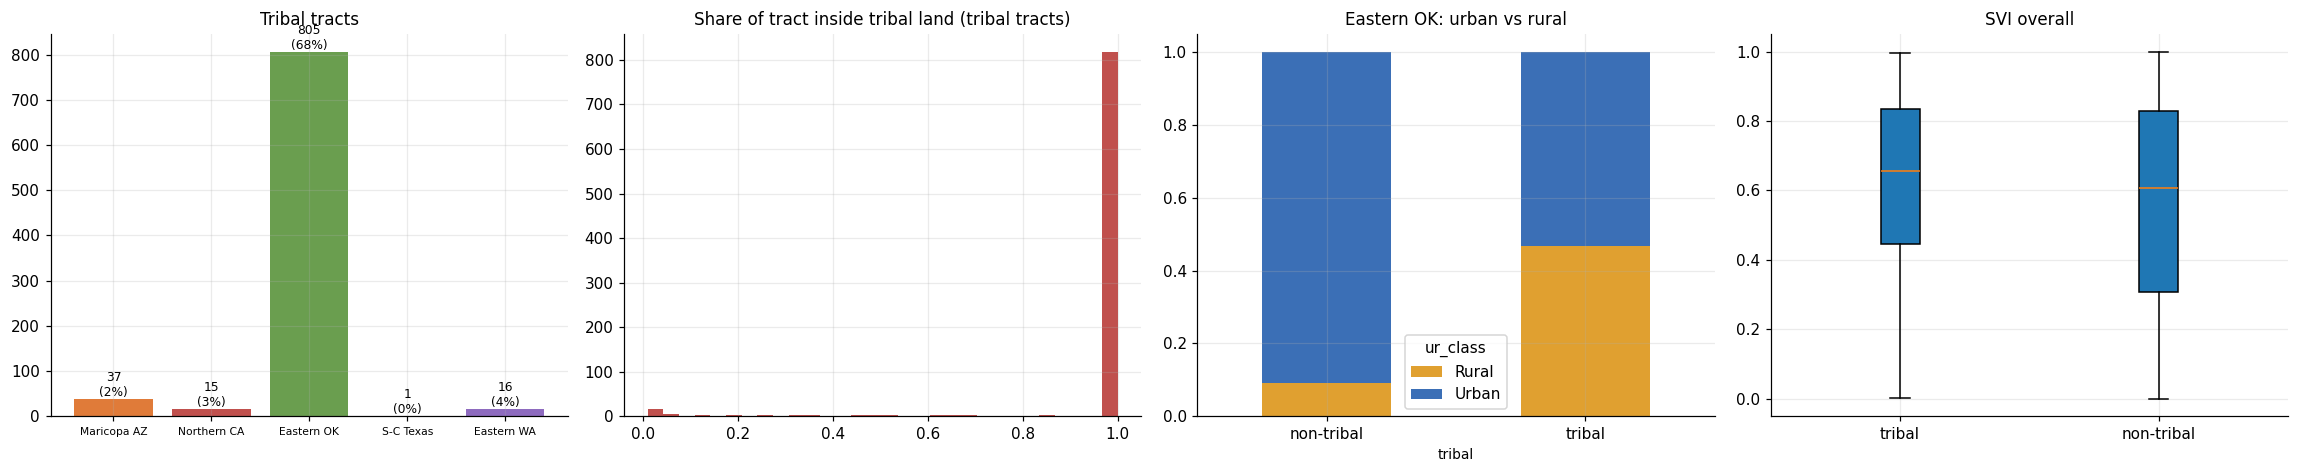

                  tribal     share  legal  stat
region                                         
maricopa-az           37  0.023227     37     0
northern-ca           15  0.025381     13     2
eastern-ok           805  0.675336     13   792
south-central-tx       1  0.000167      1     0
eastern-wa            16  0.038554     16     0

tribal tracts: 874 | Eastern OK share of them: 92%
rural share, tribal vs non-tribal (all regions): {False: 0.16, True: 0.48} | Eastern OK: {False: 0.09, True: 0.47}
median SVI tribal vs not: {False: 0.61, True: 0.66} | median pop: {False: 3976.5, True: 3217.0}


In [4]:
t = df.groupby("region").agg(tribal=("tribal", "sum"), share=("tribal", "mean"), legal=("tribal_legal", "sum"), stat=("tribal_statistical", "sum")).reindex(REG)
fig, ax = plt.subplots(1, 4, figsize=(21, 4.4)); ax[0].bar([NAME[r] for r in REG], t.tribal, color=[COL[r] for r in REG]); ax[0].set_title("Tribal tracts")
for i, (s, m_) in enumerate(zip(t.tribal, t.share)): ax[0].text(i, s, f"{int(s)}\n({m_:.0%})", ha="center", va="bottom", fontsize=8)
ax[0].tick_params(axis="x", labelsize=7); ax[1].hist(df[df.tribal].tribal_pct.dropna(), bins=30, color="#c0504d"); ax[1].set_title("Share of tract inside tribal land (tribal tracts)")
ok = df[df.region == "eastern-ok"]; pd.crosstab(ok.tribal, ok.ur_class, normalize="index").rename(index={False: "non-tribal", True: "tribal"}).plot.bar(stacked=True, ax=ax[2], rot=0, color=["#e0a030", "#3b6fb6"]); ax[2].set_title("Eastern OK: urban vs rural")
ax[3].boxplot([df.loc[df.tribal, "svi_overall"].dropna(), df.loc[~df.tribal, "svi_overall"].dropna()], patch_artist=True, showfliers=False); ax[3].set_xticklabels(["tribal", "non-tribal"]); ax[3].set_title("SVI overall")
plt.tight_layout(); plt.show(); print(t.to_string()); print(f"\ntribal tracts: {int(df.tribal.sum())} | Eastern OK share of them: {t.tribal['eastern-ok'] / t.tribal.sum():.0%}")
print("rural share, tribal vs non-tribal (all regions):", df.groupby("tribal").rural.mean().round(2).to_dict(), "| Eastern OK:", ok.groupby("tribal").rural.mean().round(2).to_dict())
print("median SVI tribal vs not:", df.groupby("tribal").svi_overall.median().round(2).to_dict(), "| median pop:", df.groupby("tribal").pop_total.median().to_dict())

**Takeaway:** 874 tracts are tribal and 92% of them (805) are in Eastern Oklahoma, where they are 68% of the region's tracts; elsewhere they are 0.02% (Texas) to 4% of tracts. In Eastern OK 792 of the 805 are statistical tribal areas, not legal reservations. Tribal tracts are more rural (48% vs 16% overall, 47% vs 9% within Eastern OK), smaller (median population 3,217 vs 3,977) and somewhat more vulnerable (median SVI 0.66 vs 0.61). Any tribal comparison is mostly an Eastern Oklahoma comparison and is entangled with rurality.

## 4. Hazard exposure by region

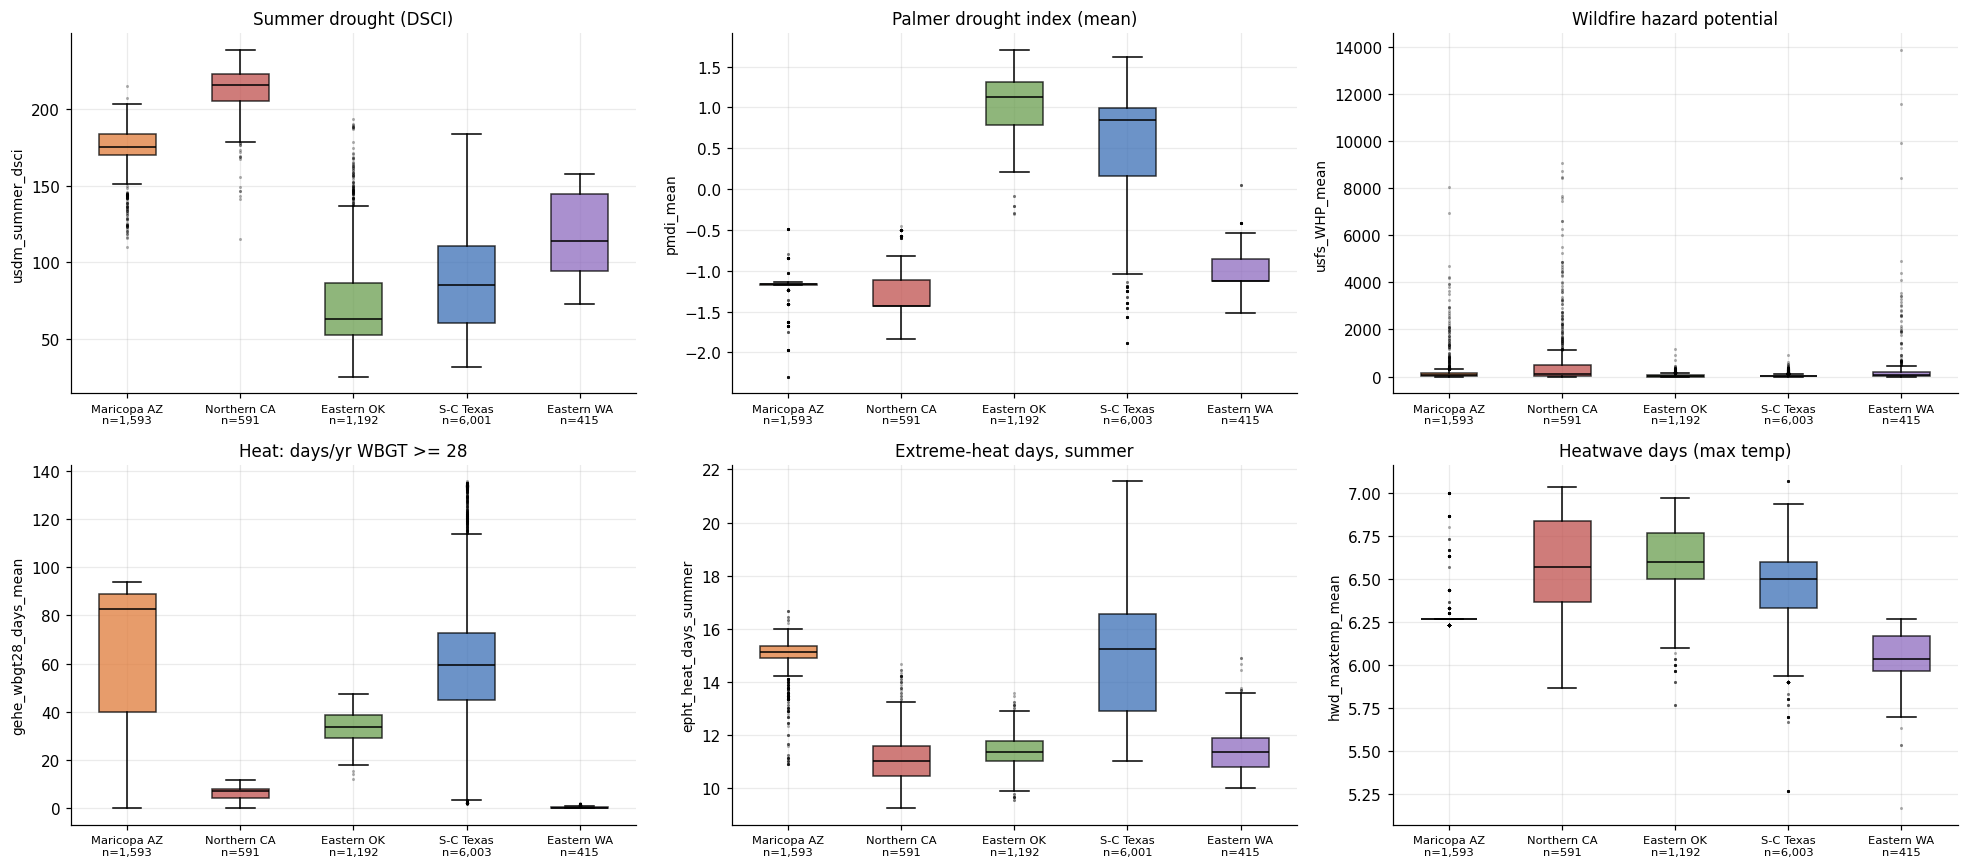

                  usdm_summer_dsci  pmdi_mean  usfs_WHP_mean  gehe_wbgt28_days_mean  epht_heat_days_summer  hwd_maxtemp_mean
region                                                                                                                      
maricopa-az                  175.6       -1.2           66.1                   82.6                   15.1               6.3
northern-ca                  216.0       -1.4          108.0                    7.3                   11.0               6.6
eastern-ok                    63.3        1.1           12.6                   33.8                   11.3               6.6
south-central-tx              85.2        0.9           18.8                   59.6                   15.2               6.5
eastern-wa                   114.2       -1.1           50.5                    0.1                   11.3               6.0

null share: {'usdm_summer_dsci': 0.0, 'pmdi_mean': 0.0, 'usfs_WHP_mean': 0.0, 'gehe_wbgt28_days_mean': 0.0, 'epht_heat_days_

In [5]:
H = [("usdm_summer_dsci", "Summer drought (DSCI)"), ("pmdi_mean", "Palmer drought index (mean)"), ("usfs_WHP_mean", "Wildfire hazard potential"), ("gehe_wbgt28_days_mean", "Heat: days/yr WBGT >= 28"), ("epht_heat_days_summer", "Extreme-heat days, summer"), ("hwd_maxtemp_mean", "Heatwave days (max temp)")]
fig, ax = plt.subplots(2, 3, figsize=(18, 8))
for a, (c, t_) in zip(ax.ravel(), H): box_by_region(a, c, title=t_)
plt.tight_layout(); plt.show(); print(df.groupby("region")[[c for c, _ in H]].median().reindex(REG).round(1).to_string()); print("\nnull share:", (df[[c for c, _ in H]].isna().mean() * 100).round(1).to_dict())

**Takeaway:** hazards are regional, not tract-level noise. Northern CA has the highest drought (summer DSCI 216) and wildfire hazard (108), Maricopa the most extreme heat (83 days/yr over WBGT 28), and Eastern WA almost none (0.1) but moderate fire and drought. Oklahoma and Texas are wetter (positive Palmer index +1.1 and +0.9, against -1.1 to -1.4 in the three western regions). Heatwave days from the max-temperature series are about 6 in every region, so that column carries almost no signal. No hazard column has missing values.

## 5. How do the strata relate to each other?

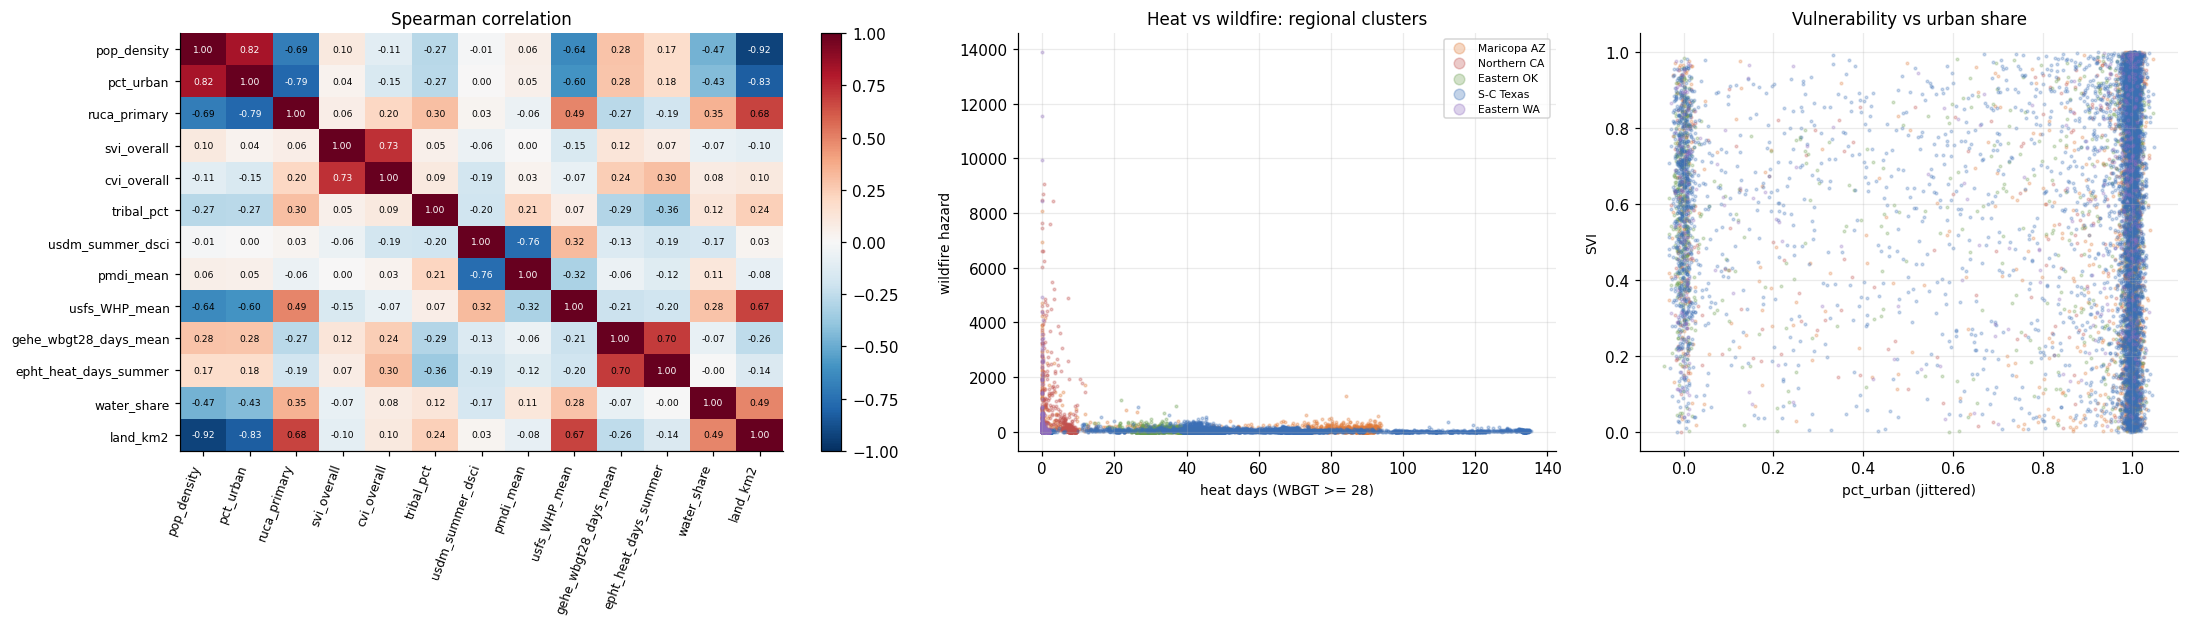

             svi_overall  cvi_overall  pct_urban  pop_density  tribal_pct
svi_overall         1.00         0.73       0.04         0.10        0.05
cvi_overall         0.73         1.00      -0.15        -0.11        0.09
pct_urban           0.04        -0.15       1.00         0.82       -0.27
tribal_pct          0.05         0.09      -0.27        -0.27        1.00


In [6]:
cols = ["pop_density", "pct_urban", "ruca_primary", "svi_overall", "cvi_overall", "tribal_pct", "usdm_summer_dsci", "pmdi_mean", "usfs_WHP_mean", "gehe_wbgt28_days_mean", "epht_heat_days_summer", "water_share", "land_km2"]
cm = df[cols].corr(method="spearman"); fig, ax = plt.subplots(1, 3, figsize=(20, 5.8), gridspec_kw={"width_ratios": [1.4, 1, 1]})
plt.colorbar(heat(ax[0], cm, fs=6, rot=70), ax=ax[0]); ax[0].set_title("Spearman correlation")
for r in REG: d_ = df[df.region == r]; ax[1].scatter(d_.gehe_wbgt28_days_mean, d_.usfs_WHP_mean, s=3, alpha=.3, color=COL[r], label=NAME[r]); ax[2].scatter(d_.pct_urban + np.random.default_rng(1).normal(0, .012, len(d_)), d_.svi_overall, s=3, alpha=.25, color=COL[r])
ax[1].set(xlabel="heat days (WBGT >= 28)", ylabel="wildfire hazard", title="Heat vs wildfire: regional clusters"); ax[1].legend(markerscale=4, fontsize=7); ax[2].set(xlabel="pct_urban (jittered)", ylabel="SVI", title="Vulnerability vs urban share")
plt.tight_layout(); plt.show(); print(cm.loc[["svi_overall", "cvi_overall", "pct_urban", "tribal_pct"], ["svi_overall", "cvi_overall", "pct_urban", "pop_density", "tribal_pct"]].round(2).to_string())

**Takeaway:** pct_urban and population density agree closely (Spearman 0.82), but SVI is nearly independent of urbanity (0.04) and CVI weakly negative with it (-0.15). Tribal land share is lower in urban tracts (-0.27). The scatter of heat days against wildfire hazard shows five regional clusters, so hazards mostly tell you which region a tract is in, and a correlation pooled over regions mixes between-region and within-region effects.

## 6. Map of vulnerability and tribal tracts

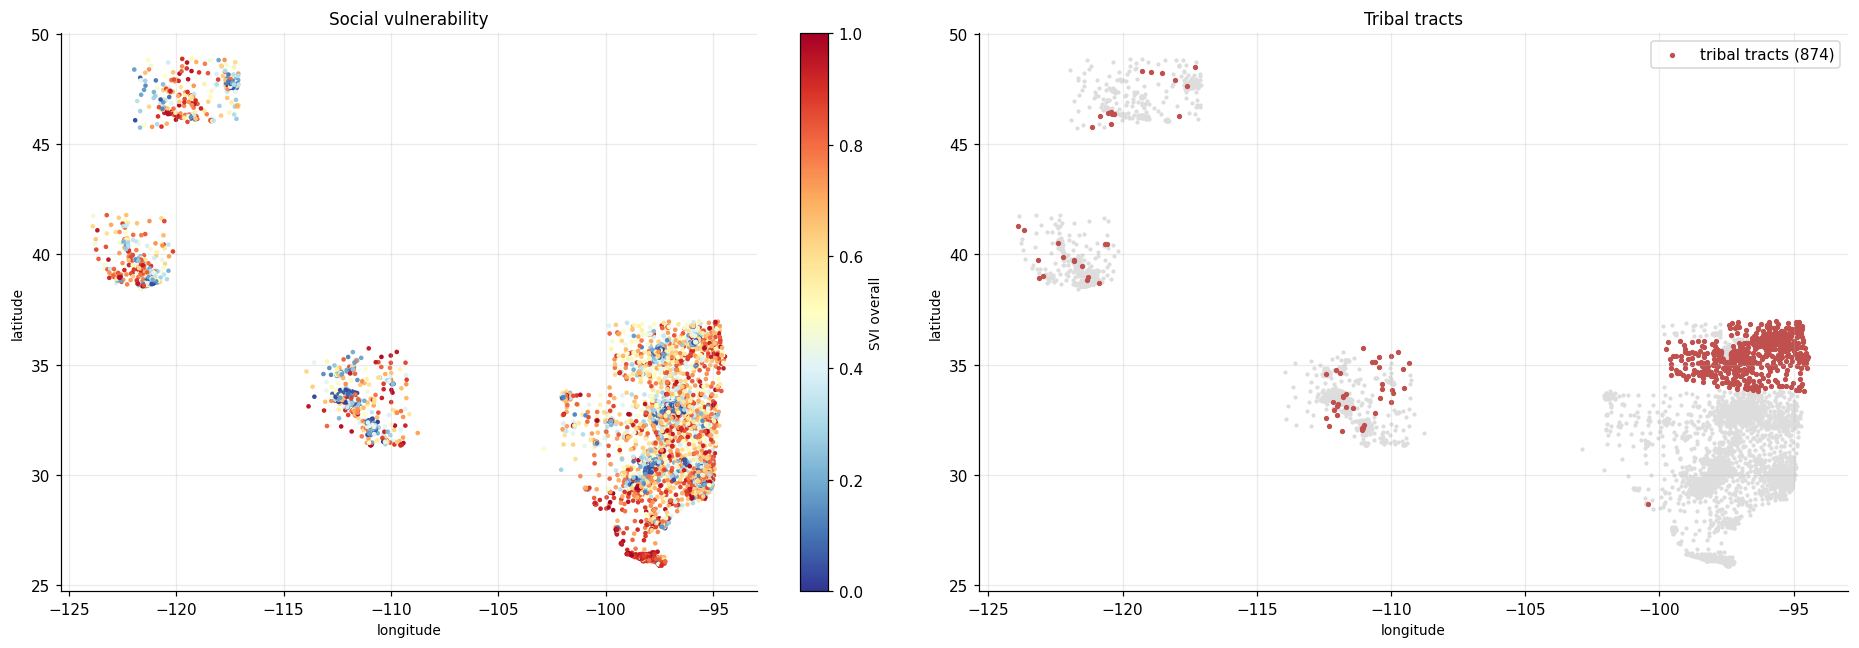

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(17, 6))
sc = ax[0].scatter(df.INTPTLON, df.INTPTLAT, c=df.svi_overall, s=4, cmap="RdYlBu_r"); plt.colorbar(sc, ax=ax[0], label="SVI overall"); ax[0].set_title("Social vulnerability")
ax[1].scatter(df.INTPTLON, df.INTPTLAT, c="#dddddd", s=3); tt = df[df.tribal]; ax[1].scatter(tt.INTPTLON, tt.INTPTLAT, c="#c0504d", s=6, label=f"tribal tracts ({len(tt)})"); ax[1].legend(); ax[1].set_title("Tribal tracts")
for a in ax: a.set(xlabel="longitude", ylabel="latitude")
plt.tight_layout(); plt.show()

**Takeaway:** SVI is patchy within regions: the Rio Grande valley at the southern tip of Texas is solidly high, and pockets of low vulnerability (blue) sit inside the metros. The tribal map shows why tribal comparisons are regional: a solid block of tribal tracts fills north-eastern Oklahoma, with only scattered ones in the other regions.